# **Aprendizaje No Supervisado con K-Means**

**Objetivo**: Utilizar K-Means para descubrir automáticamente los dos símbolos de una modulación BPSK  y 16_QAM sin conocer previamente los bits transmitidos.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Configuración de reproducibilidad y dispositivo
np.random.seed(17)

# Bits aleatorios
N = 200
bits = np.random.randint(0, 2, N)

# BPSK: 0 -> -1, 1 -> +1
symbols = 2*bits - 1

# Ruido AWGN
sigma = 0.4
rx = symbols + sigma*np.random.randn(N)


Se grafican los símbolos BPSK enviados

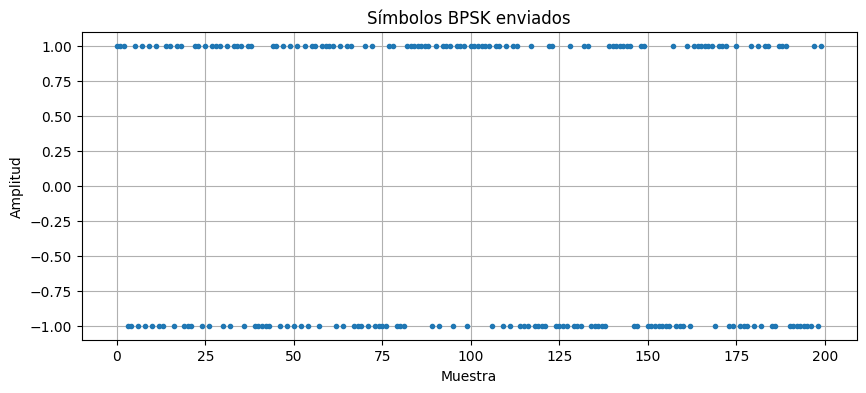

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(symbols, '.')
plt.grid(True)
plt.title("Símbolos BPSK enviados")
plt.ylabel("Amplitud")
plt.xlabel("Muestra")
plt.show()

Se grafican los símbolos BPSK recibidos

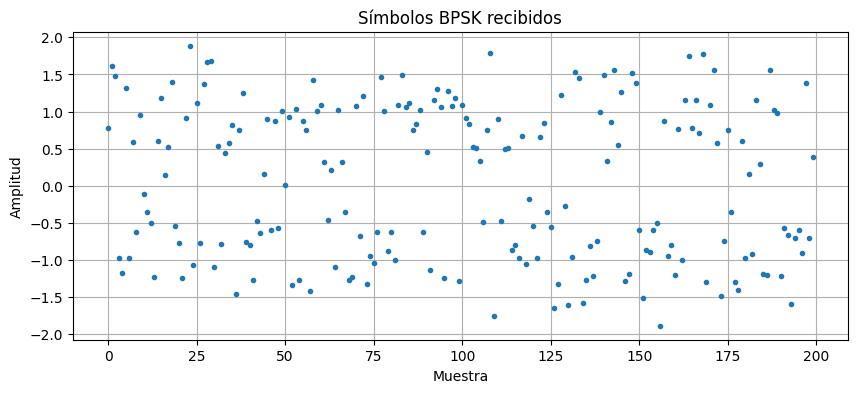

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(rx, '.')
plt.grid(True)
plt.title("Símbolos BPSK recibidos")
plt.ylabel("Amplitud")
plt.xlabel("Muestra")
plt.show()

In [ ]:
from sklearn.cluster import KMeans

X = rx.reshape(-1,1)

kmeans = KMeans(n_clusters=2,
                random_state=0,
                n_init=10)

kmeans.fit(X)

clusters = kmeans.labels_
centroids = kmeans.cluster_centers_

print("Centroides encontrados:")
print(centroids)


Centroides encontrados:
[[-0.93050033]
 [ 0.97682677]]


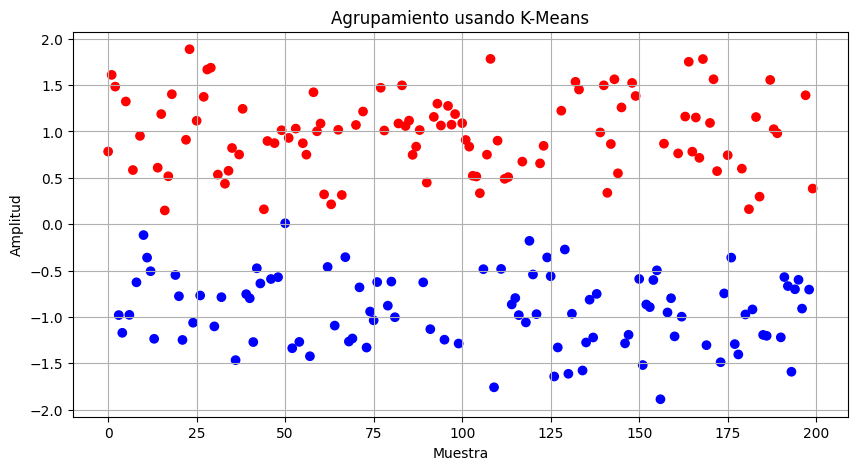

In [ ]:
plt.figure(figsize=(10,5))

plt.scatter(range(N),
            rx,
            c=clusters,
            cmap='bwr')

plt.grid(True)
plt.title("Agrupamiento usando K-Means")
plt.xlabel("Muestra")
plt.ylabel("Amplitud")

plt.show()

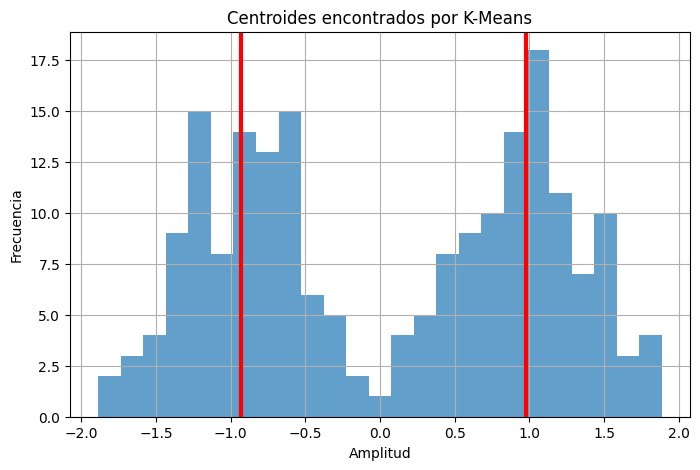

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(rx,
         bins=25,
         alpha=0.7)

for c in centroids:
    plt.axvline(c,
                color='red',
                linewidth=3)

plt.title("Centroides encontrados por K-Means")
plt.xlabel("Amplitud")
plt.ylabel("Frecuencia")
plt.grid(True)

plt.show()

# 16-QAM

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [ ]:
np.random.seed(42)

N = 1000

# Niveles permitidos
levels = np.array([-3, -1, 1, 3])

# Componentes I y Q aleatorias
I = np.random.choice(levels, N)
Q = np.random.choice(levels, N)

# Símbolos complejos
symbols = I + 1j*Q

In [ ]:
sigma = 0.5

noise = sigma * (
    np.random.randn(N) +
    1j*np.random.randn(N)
)

rx = symbols + noise

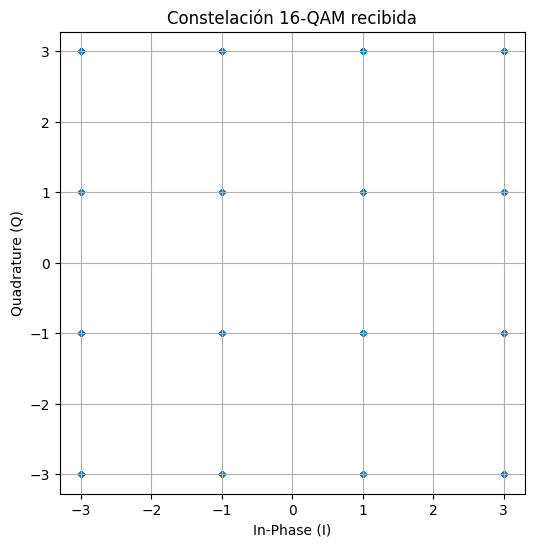

In [ ]:
plt.figure(figsize=(6,6))

plt.scatter(
    symbols.real,
    symbols.imag,
    s=10,
    alpha=0.5
)

plt.grid(True)
plt.xlabel("In-Phase (I)")
plt.ylabel("Quadrature (Q)")
plt.title("Constelación 16-QAM recibida")
plt.axis('equal')

plt.show()

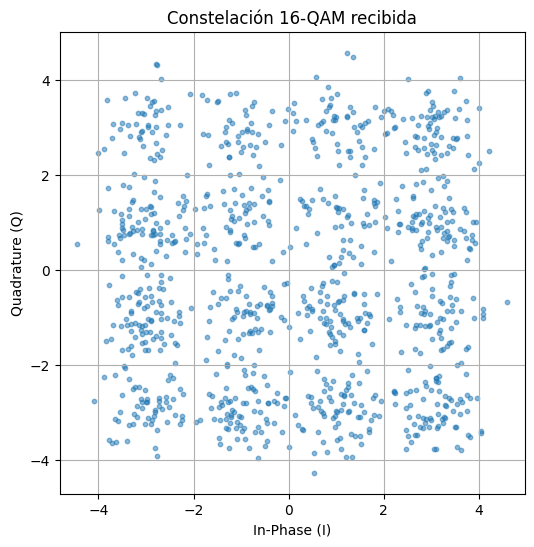

In [ ]:
plt.figure(figsize=(6,6))

plt.scatter(
    rx.real,
    rx.imag,
    s=10,
    alpha=0.5
)

plt.grid(True)
plt.xlabel("In-Phase (I)")
plt.ylabel("Quadrature (Q)")
plt.title("Constelación 16-QAM recibida")
plt.axis('equal')

plt.show()

In [ ]:
X = np.column_stack((rx.real, rx.imag))

kmeans = KMeans(
    n_clusters=16,
    random_state=0,
    n_init=20
)

kmeans.fit(X)

labels = kmeans.labels_
centroids = kmeans.cluster_centers_
kmeans.fit(X)

KMeans(n_clusters=16, n_init=20, random_state=0)

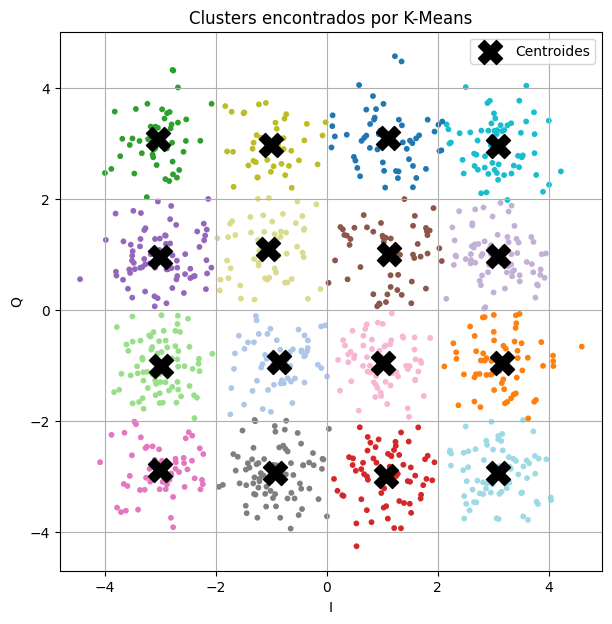

In [ ]:
plt.figure(figsize=(7,7))

plt.scatter(
    X[:,0],
    X[:,1],
    c=labels,
    cmap='tab20',
    s=10
)

plt.scatter(
    centroids[:,0],
    centroids[:,1],
    color='black',
    marker='X',
    s=300,
    label='Centroides'
)

plt.grid(True)
plt.xlabel("I")
plt.ylabel("Q")
plt.title("Clusters encontrados por K-Means")
plt.legend()
plt.axis('equal')

plt.show()

In [ ]:
print("Centroides encontrados:")

for i,c in enumerate(centroids):
    print(f"Cluster {i+1}: {c}")

Centroides encontrados:
Cluster 1: [1.10428096 3.09110937]
Cluster 2: [-0.86771156 -0.93671952]
Cluster 3: [ 3.15183933 -0.96368338]
Cluster 4: [-3.03709767  3.0756292 ]
Cluster 5: [-2.98813657 -1.01445728]
Cluster 6: [ 1.06892297 -3.00127928]
Cluster 7: [-2.99917327  0.94320504]
Cluster 8: [3.08224119 0.96962865]
Cluster 9: [1.12983565 0.99785596]
Cluster 10: [-3.00115512 -2.89097923]
Cluster 11: [ 1.00769082 -0.95993301]
Cluster 12: [-0.9319296  -2.94886065]
Cluster 13: [-1.00991224  2.96283822]
Cluster 14: [-1.06071211  1.08574681]
Cluster 15: [3.08686281 2.94620681]
Cluster 16: [ 3.08980471 -2.94595468]


# Aprender el valor de K


K óptimo = 16
Silhouette Score = 0.4827


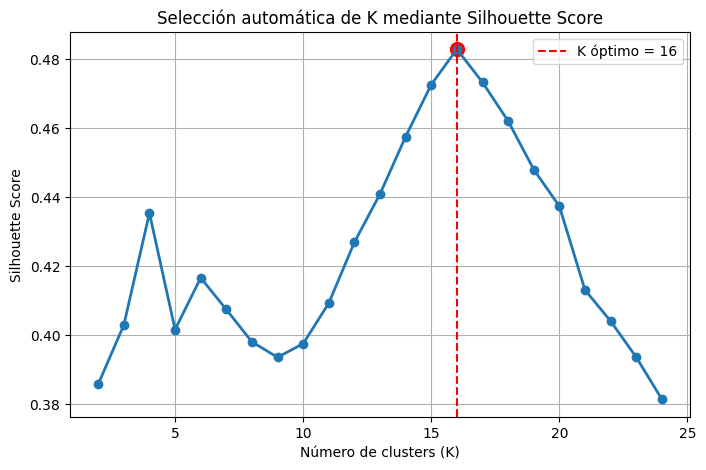

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np
import matplotlib.pyplot as plt

# Rango de K a evaluar
K_range = range(2, 25)

scores = []

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=0,
        n_init=20
    )

    labels = kmeans.fit_predict(X)

    score = silhouette_score(X, labels)

    scores.append(score)

# Encontrar el mejor K
best_k = K_range[np.argmax(scores)]
best_score = max(scores)

print(f"K óptimo = {best_k}")
print(f"Silhouette Score = {best_score:.4f}")

# Gráfica
plt.figure(figsize=(8,5))

plt.plot(K_range,
         scores,
         marker='o',
         linewidth=2)

plt.axvline(best_k,
            color='red',
            linestyle='--',
            label=f'K óptimo = {best_k}')

plt.scatter(best_k,
            best_score,
            color='red',
            s=100)

plt.xlabel("Número de clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Selección automática de K mediante Silhouette Score")
plt.grid(True)
plt.legend()

plt.show()


# Varios niveles de SNR

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Generar 16-QAM ideal
N = 2000
levels = np.array([-3, -1, 1, 3])

I = np.random.choice(levels, N)
Q = np.random.choice(levels, N)

symbols = I + 1j*Q

# Distintos niveles de ruido
sigmas = [0.1, 0.3, 0.5, 0.8, 1.2, 1.8]

best_K_list = []
best_score_list = []

for sigma in sigmas:

    noise = sigma * (
        np.random.randn(N) +
        1j*np.random.randn(N)
    )

    rx = symbols + noise

    X = np.column_stack((rx.real, rx.imag))

    scores = []

    for k in range(2, 25):

        kmeans = KMeans(
            n_clusters=k,
            random_state=0,
            n_init=20
        )

        labels = kmeans.fit_predict(X)

        score = silhouette_score(X, labels)
        scores.append(score)

    best_k = np.argmax(scores) + 2
    best_score = max(scores)

    best_K_list.append(best_k)
    best_score_list.append(best_score)

    print(f"σ={sigma:.1f}  ->  K óptimo={best_k:2d}   Score={best_score:.4f}")

σ=0.1  ->  K óptimo=16   Score=0.9073
σ=0.3  ->  K óptimo=16   Score=0.6834
σ=0.5  ->  K óptimo=16   Score=0.4866
σ=0.8  ->  K óptimo= 4   Score=0.4038
σ=1.2  ->  K óptimo= 4   Score=0.3650
σ=1.8  ->  K óptimo= 3   Score=0.3483


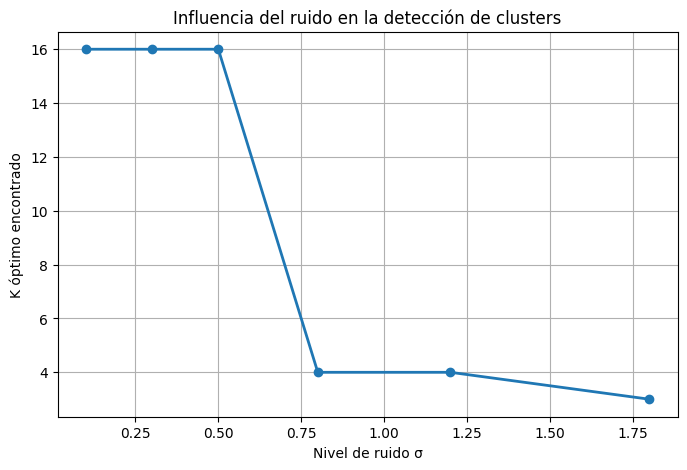

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(sigmas,
         best_K_list,
         marker='o',
         linewidth=2)

plt.xlabel("Nivel de ruido σ")
plt.ylabel("K óptimo encontrado")
plt.title("Influencia del ruido en la detección de clusters")
plt.grid(True)

plt.show()

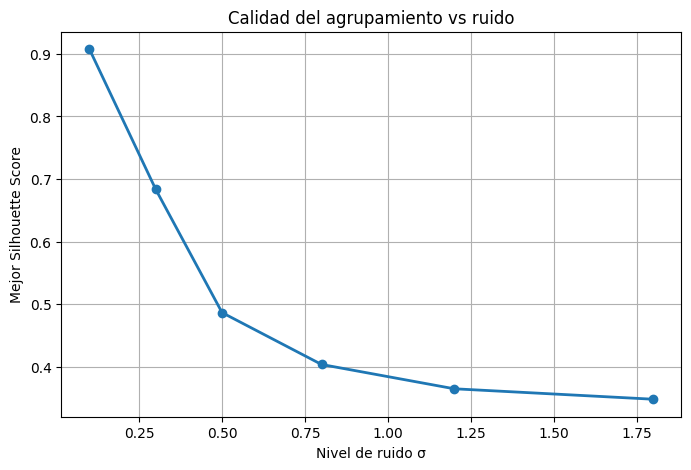

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(sigmas,
         best_score_list,
         marker='o',
         linewidth=2)

plt.xlabel("Nivel de ruido σ")
plt.ylabel("Mejor Silhouette Score")
plt.title("Calidad del agrupamiento vs ruido")
plt.grid(True)

plt.show()

jajajaja